In [3]:
import pandas as pd

df = pd.read_csv("dados/credit_risk_dataset.csv")

print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
display(df.head())

Linhas: 32581 | Colunas: 12


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## Fase 1 — Análise exploratória dos dados

Nesta etapa, vamos analisar o perfil dos clientes e dos empréstimos e verificar a proporção de inadimplentes na base.

In [4]:
# Mostra os tipos das colunas e quantos valores estão preenchidos
df.info()

# Resume as variáveis numéricas, com uma variável por linha
display(df.describe().T.round(2))

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.73,6.35,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.85,61983.12,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.37,6322.09,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.22,0.41,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.80,4.06,2.00,3.00,4.00,8.00,30.00


A renda média é de 66.074,85, acima da mediana de 55.000. O valor máximo de 6.000.000 sugere que rendas muito altas influenciam a média. Por isso, usaremos também a mediana para descrever o perfil de renda dos clientes. A idade máxima de 144 anos e o tempo de emprego máximo de 123 anos merecem investigação na etapa de limpeza. Também identificamos 895 registros sem tempo de emprego e 3.116 sem taxa de juros.

In [5]:
quantidade = df["loan_status"].value_counts().sort_index()

resumo = quantidade.to_frame(name="quantidade")
resumo["percentual"] = (quantidade / len(df) * 100).round(2)

display(resumo)

,quantidade,percentual
loan_status,,
0,25473,78.18
1,7108,21.82


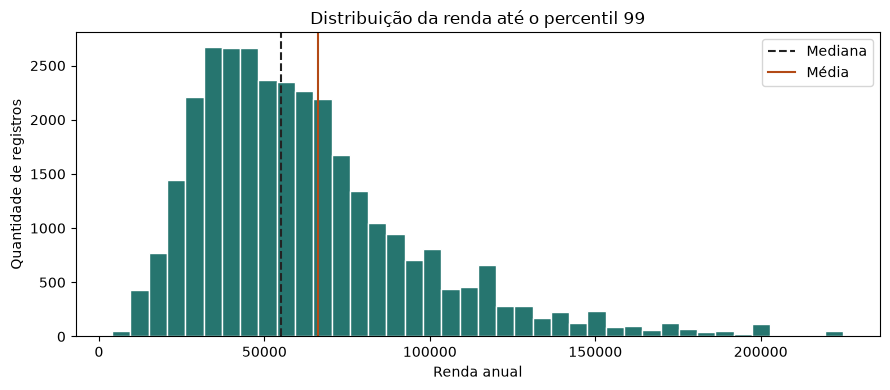

In [6]:
import matplotlib.pyplot as plt

renda = df["person_income"]
limite = renda.quantile(0.99)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(renda[renda <= limite], bins=40, color="#26756F", edgecolor="white")

ax.axvline(renda.median(), color="#222222", linestyle="--", label="Mediana")
ax.axvline(renda.mean(), color="#B34A16", linestyle="-", label="Média")

ax.set_title("Distribuição da renda até o percentil 99")
ax.set_xlabel("Renda anual")
ax.set_ylabel("Quantidade de registros")
ax.legend()

plt.tight_layout()
plt.show()

A média da renda (66.074,85) aparece à direita da mediana (55.000), o que indica a influência das rendas mais altas. Para visualizar melhor as faixas em que os registros se concentram, o histograma exibe as rendas até o percentil 99. A mediana e a média foram calculadas com todos os registros.

Linhas duplicadas: 165


,nulos,percentual_%
person_age,0,0.00
person_income,0,0.00
person_home_ownership,0,0.00
person_emp_length,895,2.75
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_int_rate,3116,9.56
loan_status,0,0.00
loan_percent_income,0,0.00


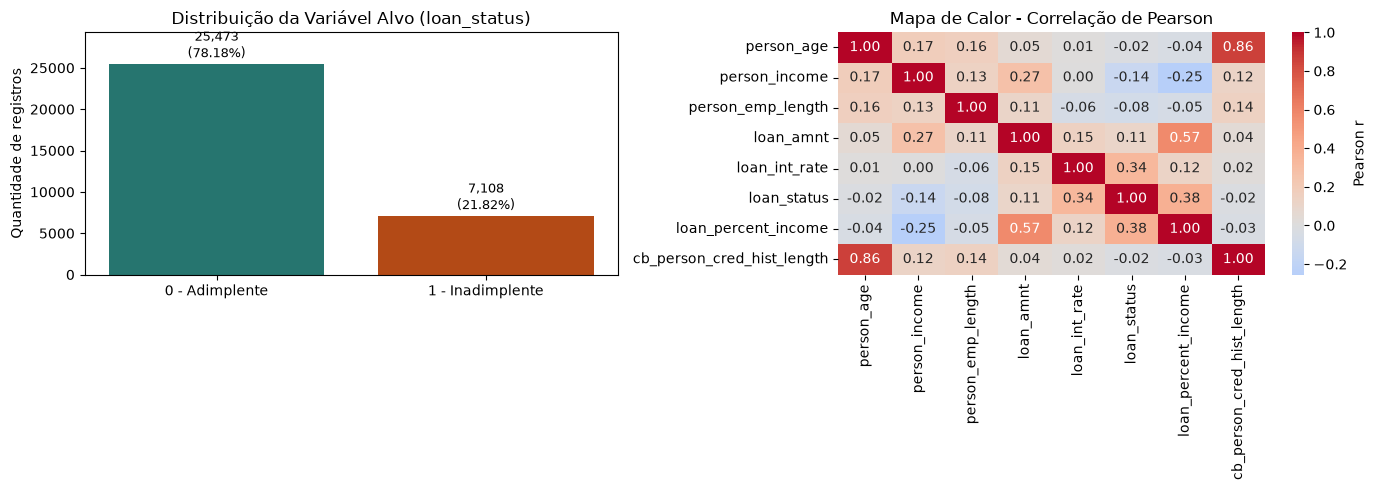

In [7]:
import seaborn as sns

print(f"Linhas duplicadas: {df.duplicated().sum()}")

nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)
display(pd.DataFrame({"nulos": nulos, "percentual_%": nulos_pct}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 2: Distribuição da variável alvo
counts = df["loan_status"].value_counts().sort_index()
bars = axes[0].bar(
    ["0 - Adimplente", "1 - Inadimplente"],
    counts.values,
    color=["#26756F", "#B34A16"]
)
axes[0].set_title("Distribuição da Variável Alvo (loan_status)")
axes[0].set_ylabel("Quantidade de registros")
axes[0].set_ylim(0, counts.max() * 1.15)

for bar, qtd in zip(bars, counts.values):
    pct = qtd / len(df) * 100
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 300,
        f"{qtd:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Gráfico 3: Mapa de calor de correlação de Pearson
num_cols = df.select_dtypes(include="number").columns
corr = df[num_cols].corr(method="pearson")
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[1],
    cbar_kws={"label": "Pearson r"}
)
axes[1].set_title("Mapa de Calor - Correlação de Pearson")

plt.tight_layout()
plt.show()

### Tomada de decisão (Fase 1 -> Próximas Fases)

A base conta com **32.581 registros** e **12 colunas**, apresentando **165 linhas duplicadas** e valores ausentes em `loan_int_rate` (**3.116 nulos**, 9,56%) e `person_emp_length` (**895 nulos**, 2,75%). A variável alvo `loan_status` é desbalanceada (**78,18%** de adimplentes `0` e **21,82%** de inadimplentes `1`), o que exige `stratify=y` na divisão treino/teste e balanceamento **apenas no conjunto de treino** para evitar *data leakage*.

No mapa de calor de Pearson, `loan_percent_income` (+0,38) e `loan_int_rate` (+0,34) têm as maiores correlações lineares positivas com inadimplência, enquanto `person_age` e `cb_person_cred_hist_length` têm correlação alta entre si (+0,86). Como há assimetria à direita e valores extremos (como `person_income` até 6.000.000, `person_age` até 144 e `person_emp_length` até 123), usaremos a **mediana** onde houver assimetria/outliers e avaliaremos o tratamento de *outliers* na Fase 2 considerando que o **KNN** é sensível a distâncias/outliers e a **Árvore de Decisão** é robusta a eles. Na Fase 3, criaremos `comprometimento_renda = (loan_amnt / person_income) * 100` após tratar os nulos originais.